In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("SkillBridge AI - EDA Environment Ready!")

SkillBridge AI - EDA Environment Ready!


In [10]:
import pandas as pd

# O*NET veri setleri

occupations = pd.read_excel("/content/Occupation Data.xlsx")

skills = pd.read_excel("/content/Essential Skills.xlsx")

knowledge = pd.read_excel("/content/Knowledge.xlsx")

# Coursera veri seti

coursera = pd.read_csv("/content/coursera_course_2024.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


=== DATASET OVERVIEW ===

O*NET Occupations
Rows: 1016
Columns: 3
Missing values: 0
Duplicate rows: 0

O*NET Essential Skills
Rows: 18200
Columns: 15
Missing values: 9100
Duplicate rows: 0

O*NET Knowledge
Rows: 60060
Columns: 15
Missing values: 99416
Duplicate rows: 0

Coursera Courses
Rows: 6645
Columns: 14
Missing values: 8526
Duplicate rows: 0


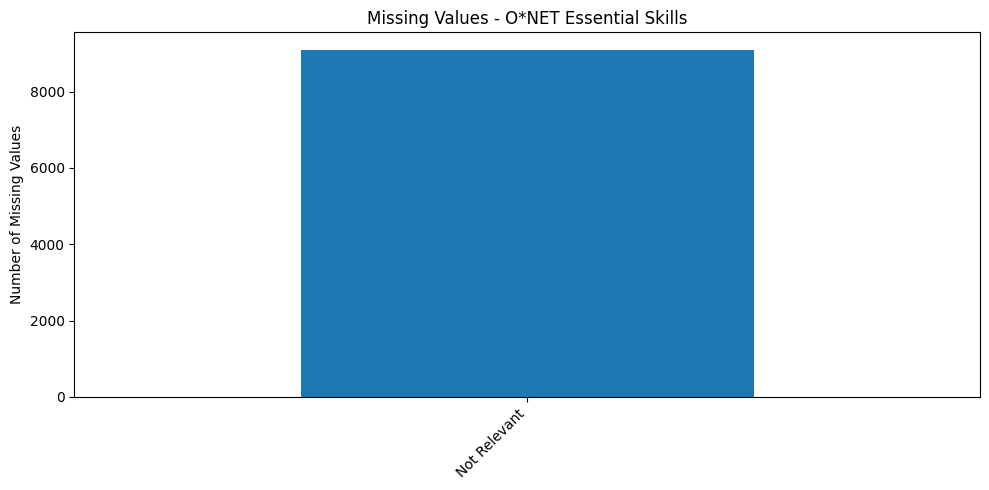

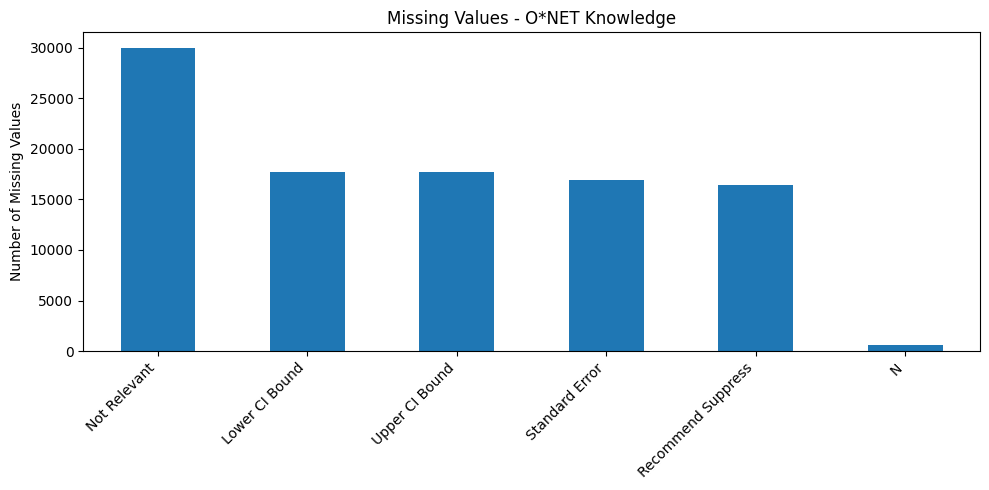

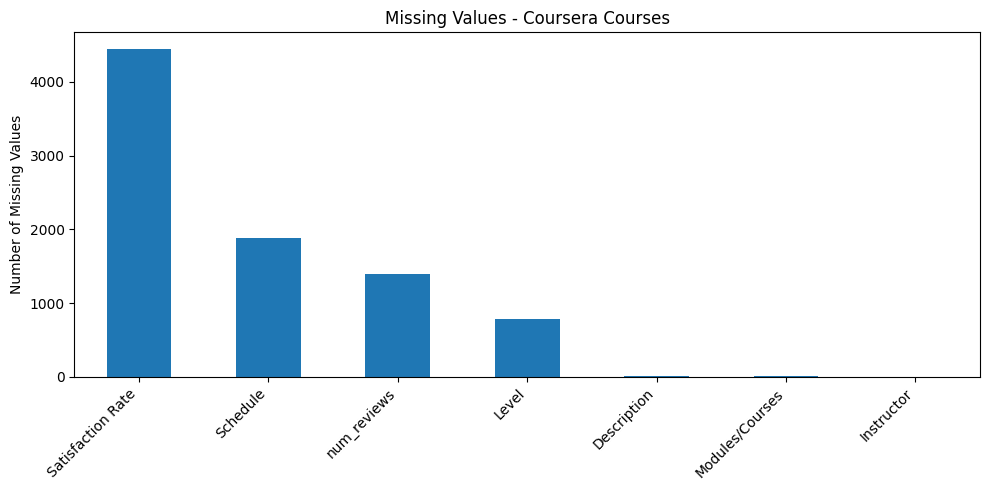


=== COURSERA COLUMNS ===
['Unnamed: 0', 'title', 'enrolled', 'rating', 'num_reviews', 'Instructor', 'Organization', 'Skills', 'Description', 'Modules/Courses', 'Level', 'Schedule', 'URL', 'Satisfaction Rate']


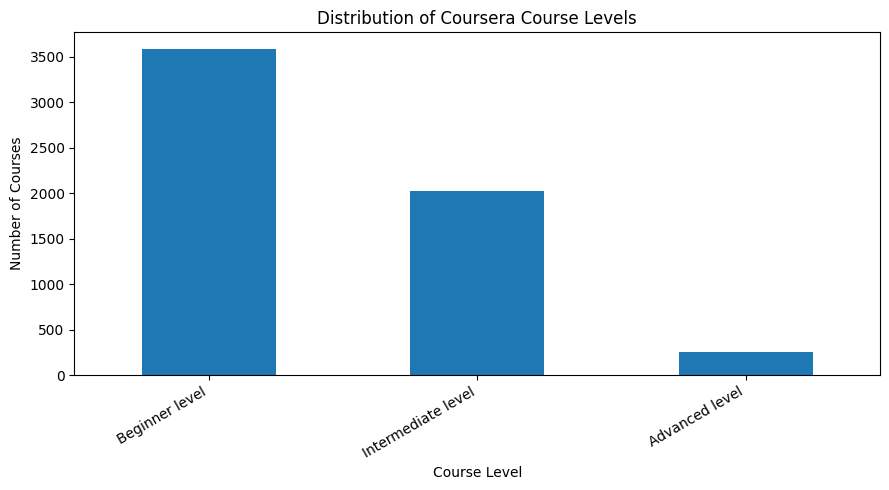


=== O*NET SKILLS COLUMNS ===
['O*NET-SOC Code', 'Title', 'Element ID', 'Element Name', 'Scale ID', 'Scale Name', 'Data Value', 'N', 'Standard Error', 'Lower CI Bound', 'Upper CI Bound', 'Recommend Suppress', 'Not Relevant', 'Date', 'Domain Source']


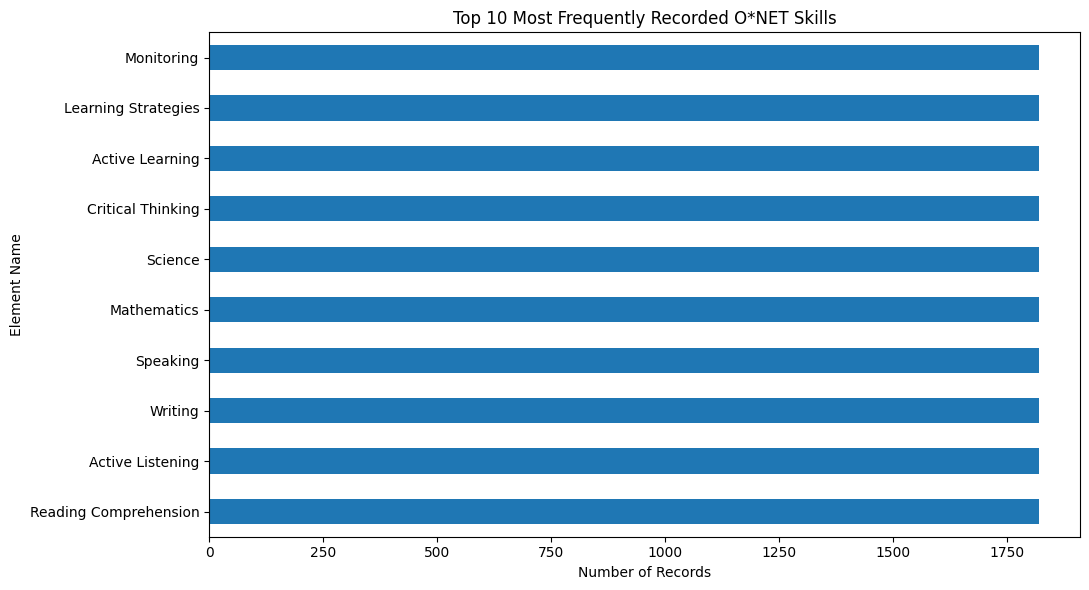


=== COURSERA SKILLS SAMPLE ===
0                                                   []
1                                                   []
2    ['web interactivty', 'Jquery', 'Data Manipulat...
3                                                   []
4    ['Cardiovascular training', 'Resistance traini...
Name: Skills, dtype: object

EDA completed!
Graphs saved in: /content/eda_results


In [11]:
import pandas as pd

import matplotlib.pyplot as plt

from pathlib import Path

# Grafiklerin kaydedileceği klasör

output = Path("/content/eda_results")

output.mkdir(exist_ok=True)

# 1. DATASET OVERVIEW

datasets = {

    "O*NET Occupations": occupations,

    "O*NET Essential Skills": skills,

    "O*NET Knowledge": knowledge,

    "Coursera Courses": coursera

}

print("=== DATASET OVERVIEW ===")

for name, df in datasets.items():

    print(f"\n{name}")

    print("Rows:", df.shape[0])

    print("Columns:", df.shape[1])

    print("Missing values:", df.isnull().sum().sum())

    print("Duplicate rows:", df.duplicated().sum())

# 2. MISSING VALUES

for name, df in datasets.items():

    missing = df.isnull().sum()

    missing = missing[missing > 0].sort_values(ascending=False)

    if not missing.empty:

        plt.figure(figsize=(10, 5))

        missing.head(15).plot(kind="bar")

        plt.title(f"Missing Values - {name}")

        plt.ylabel("Number of Missing Values")

        plt.xticks(rotation=45, ha="right")

        plt.tight_layout()

        filename = name.lower().replace(" ", "_")

        plt.savefig(output / f"{filename}_missing.png")

        plt.show()

# 3. COURSERA COURSE LEVELS

print("\n=== COURSERA COLUMNS ===")

print(coursera.columns.tolist())

level_col = next(

    (col for col in coursera.columns if "level" in col.lower()),

    None

)

if level_col:

    plt.figure(figsize=(9, 5))

    coursera[level_col].value_counts().plot(kind="bar")

    plt.title("Distribution of Coursera Course Levels")

    plt.xlabel("Course Level")

    plt.ylabel("Number of Courses")

    plt.xticks(rotation=30, ha="right")

    plt.tight_layout()

    plt.savefig(output / "coursera_course_levels.png")

    plt.show()

# 4. O*NET SKILLS

print("\n=== O*NET SKILLS COLUMNS ===")

print(skills.columns.tolist())

skill_col = next(

    (col for col in skills.columns if "element name" in col.lower()),

    None

)

if skill_col:

    plt.figure(figsize=(11, 6))

    skills[skill_col].value_counts().head(10).plot(kind="barh")

    plt.title("Top 10 Most Frequently Recorded O*NET Skills")

    plt.xlabel("Number of Records")

    plt.tight_layout()

    plt.savefig(output / "onet_top_skills.png")

    plt.show()

# 5. COURSERA SKILLS

course_skill_col = next(

    (col for col in coursera.columns if col.lower() == "skills"),

    None

)

if course_skill_col:

    print("\n=== COURSERA SKILLS SAMPLE ===")

    print(coursera[course_skill_col].dropna().head())

print("\nEDA completed!")

print("Graphs saved in:", output)

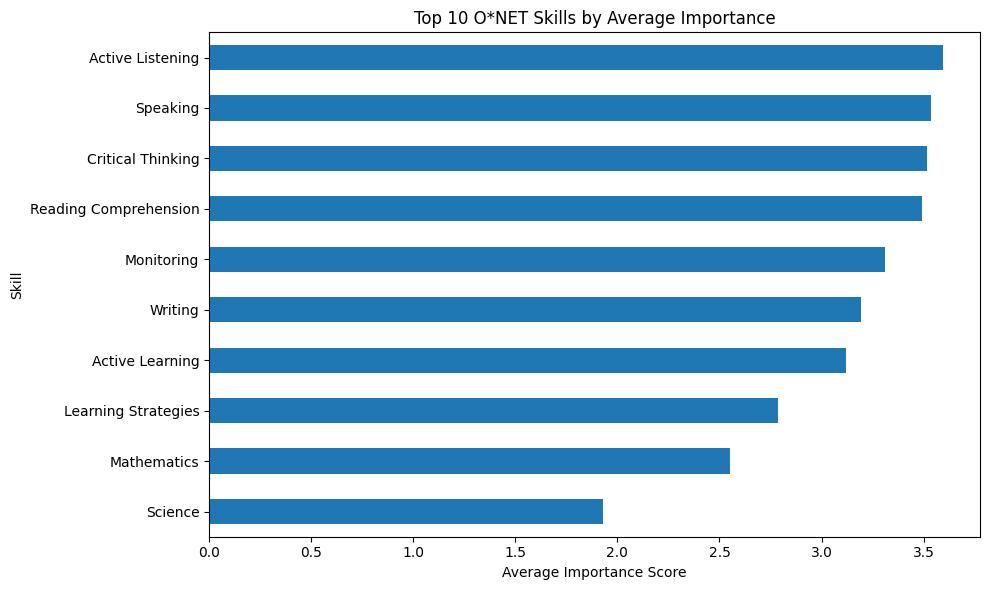

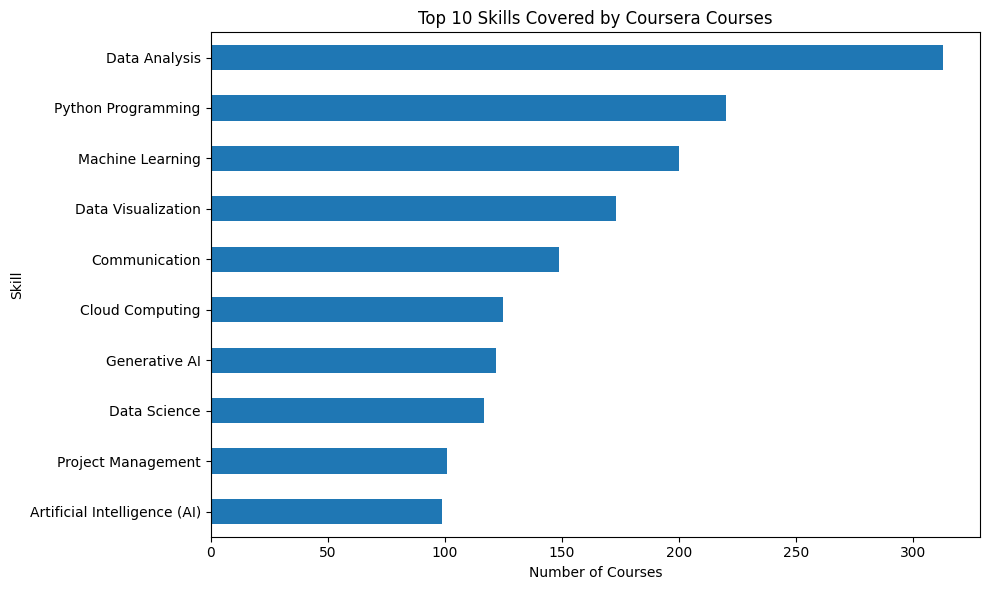

Additional EDA graphs completed!


In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import ast

# 1. O*NET: Average Skill Importance

onet_importance = skills[
    skills["Scale ID"] == "IM"
].copy()

onet_importance["Data Value"] = pd.to_numeric(
    onet_importance["Data Value"], errors="coerce"
)

top_skills = (
    onet_importance
    .groupby("Element Name")["Data Value"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
top_skills.sort_values().plot(kind="barh")

plt.title("Top 10 O*NET Skills by Average Importance")
plt.xlabel("Average Importance Score")
plt.ylabel("Skill")
plt.tight_layout()

plt.savefig("/content/eda_results/onet_skill_importance.png")
plt.show()


# 2. Coursera: Most Common Course Skills

def parse_skills(value):
    if pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(str(value))
        if isinstance(parsed, list):
            return parsed
    except (ValueError, SyntaxError):
        pass

    return []

all_course_skills = []

for value in coursera["Skills"]:
    all_course_skills.extend(parse_skills(value))

skill_counts = pd.Series(all_course_skills).value_counts().head(10)

plt.figure(figsize=(10, 6))
skill_counts.sort_values().plot(kind="barh")

plt.title("Top 10 Skills Covered by Coursera Courses")
plt.xlabel("Number of Courses")
plt.ylabel("Skill")
plt.tight_layout()

plt.savefig("/content/eda_results/coursera_top_skills.png")
plt.show()

print("Additional EDA graphs completed!")

In [13]:
# Create copies of the original datasets
occupations_clean = occupations.copy()
skills_clean = skills.copy()
knowledge_clean = knowledge.copy()
coursera_clean = coursera.copy()

# Remove fully duplicated rows
occupations_clean = occupations_clean.drop_duplicates()
skills_clean = skills_clean.drop_duplicates()
knowledge_clean = knowledge_clean.drop_duplicates()
coursera_clean = coursera_clean.drop_duplicates()

# Remove unnecessary index column if present
coursera_clean = coursera_clean.drop(
    columns=["Unnamed: 0"],
    errors="ignore"
)

# Standardize text fields
for col in ["title", "Level"]:
    if col in coursera_clean.columns:
        coursera_clean[col] = (
            coursera_clean[col]
            .astype("string")
            .str.strip()
        )

# Check missing values in important course fields
important_columns = [
    col for col in ["title", "Skills", "Description", "Level"]
    if col in coursera_clean.columns
]

print("=== COURSERA IMPORTANT FIELDS ===")
print(coursera_clean[important_columns].isnull().sum())

print("\n=== CLEANED DATASET SIZES ===")
print("Occupations:", occupations_clean.shape)
print("Essential Skills:", skills_clean.shape)
print("Knowledge:", knowledge_clean.shape)
print("Coursera:", coursera_clean.shape)

print("\nData preprocessing completed!")

=== COURSERA IMPORTANT FIELDS ===
title            0
Skills           0
Description     10
Level          778
dtype: int64

=== CLEANED DATASET SIZES ===
Occupations: (1016, 3)
Essential Skills: (18200, 15)
Knowledge: (60060, 15)
Coursera: (6645, 13)

Data preprocessing completed!
